# DSCI 552 — Homework 5

- **Name:** Yiming Lu
- **GitHub Username:** YeeDaco

All imports are in the first code cell (see `requirements.txt`). The data is loaded by the relative paths `../data/acute_inflammations/` and `../data/communities_and_crime/`, so the notebook should be run from the `notebook/` folder.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from xgboost import XGBRegressor

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
SEED = 552

## 1. Decision Trees as Interpretable Models

### (a) Acute Inflammations data

The data was downloaded from the UCI repository and is stored in `../data/acute_inflammations/`. `diagnosis.data` is a UTF-16 text file with tab-separated columns and a decimal comma in the temperature (e.g. `35,5`). There are 120 patients, 6 attributes (temperature plus five yes/no symptoms) and two yes/no labels:

- `inflammation` — inflammation of urinary bladder (d1)
- `nephritis` — nephritis of renal pelvis origin (d2)

In [2]:
AI_DIR = Path("../data/acute_inflammations")
FEATURES_AI = ["temperature", "nausea", "lumbar_pain", "urine_pushing",
               "micturition_pains", "burning_urethra"]
LABELS_AI = ["inflammation", "nephritis"]

ai = pd.read_csv(AI_DIR / "diagnosis.data", sep="\t", encoding="utf-16", header=None,
                 decimal=",", names=FEATURES_AI + LABELS_AI)
yes_no = FEATURES_AI[1:] + LABELS_AI
ai[yes_no] = (ai[yes_no].apply(lambda s: s.str.strip()) == "yes").astype(int)
print(ai.shape)
ai.head()

(120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


In [3]:
X_ai = ai[FEATURES_AI]
Y_ai = ai[LABELS_AI]
print(ai.groupby(LABELS_AI).size().rename("count"))
print()
print("label correlation:", round(Y_ai.corr().iloc[0, 1], 3))

inflammation  nephritis
0             0            30
              1            31
1             0            40
              1            19
Name: count, dtype: int64

label correlation: -0.189


### (b) Decision tree on the whole data set

The data set is multi-label (each patient can have none, one or both diseases). Following the footnote, there are three ways to handle this:

1. **Label powerset** — treat every combination of labels as one class. With two binary labels there are at most 4 classes, and all 4 occur in the data (30 / 31 / 40 / 19 patients), so this is a small, balanced 4-class problem.
2. **Binary relevance** — build one tree per label and ignore any dependence between the labels.
3. **Multi-output tree** — scikit-learn's `DecisionTreeClassifier` accepts a 2-column `y` directly; each leaf predicts both labels.

**Is the label powerset the more relevant approach here? Yes.** With only 2 labels the powerset is tiny (4 classes), so it does not suffer from the usual problem of the method (many rare label combinations). One tree then describes the full diagnosis (neither disease / inflammation only / nephritis only / both), so the IF-THEN rules read as complete diagnoses, which is what we want from an interpretable model. It also keeps the joint structure of the two labels, which binary relevance throws away. The main tree below uses the label powerset; the multi-output tree and the binary-relevance trees are shown afterwards for comparison.

In [4]:
CLASS_NAMES = {(0, 0): "none", (1, 0): "inflammation only", (0, 1): "nephritis only", (1, 1): "both"}
y_lp = Y_ai.apply(lambda r: CLASS_NAMES[(r["inflammation"], r["nephritis"])], axis=1)
print(y_lp.value_counts())

tree_full = DecisionTreeClassifier(random_state=SEED).fit(X_ai, y_lp)
print()
print("depth:", tree_full.get_depth(), "| leaves:", tree_full.get_n_leaves(),
      "| training accuracy:", accuracy_score(y_lp, tree_full.predict(X_ai)))

inflammation only    40
nephritis only       31
none                 30
both                 19
Name: count, dtype: int64

depth: 4 | leaves: 6 | training accuracy: 1.0


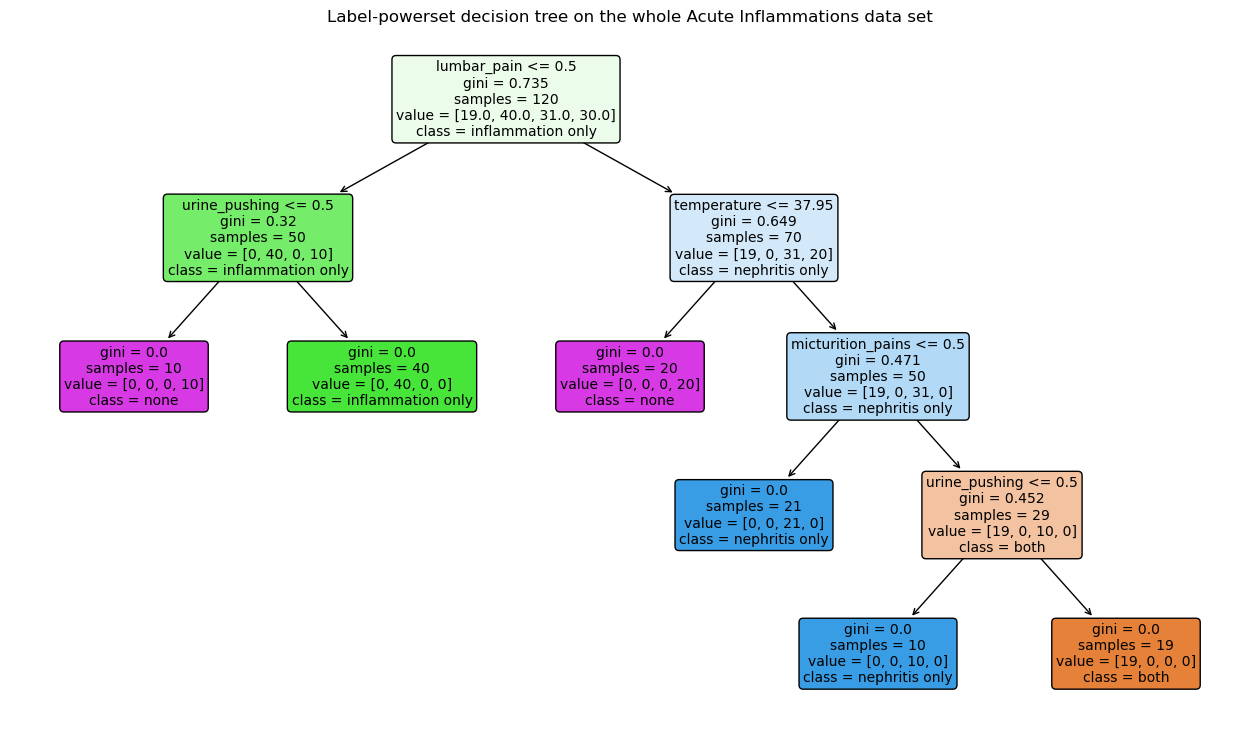

In [5]:
fig, ax = plt.subplots(figsize=(16, 9))
plot_tree(tree_full, feature_names=FEATURES_AI, class_names=list(tree_full.classes_),
          filled=True, rounded=True, impurity=True, fontsize=10, ax=ax)
ax.set_title("Label-powerset decision tree on the whole Acute Inflammations data set")
plt.show()

For comparison: the scikit-learn multi-output tree (one tree, two outputs) and the binary-relevance trees (one tree per label).

multi-output tree: depth 4 | leaves 6 | exact-match training accuracy 1.0


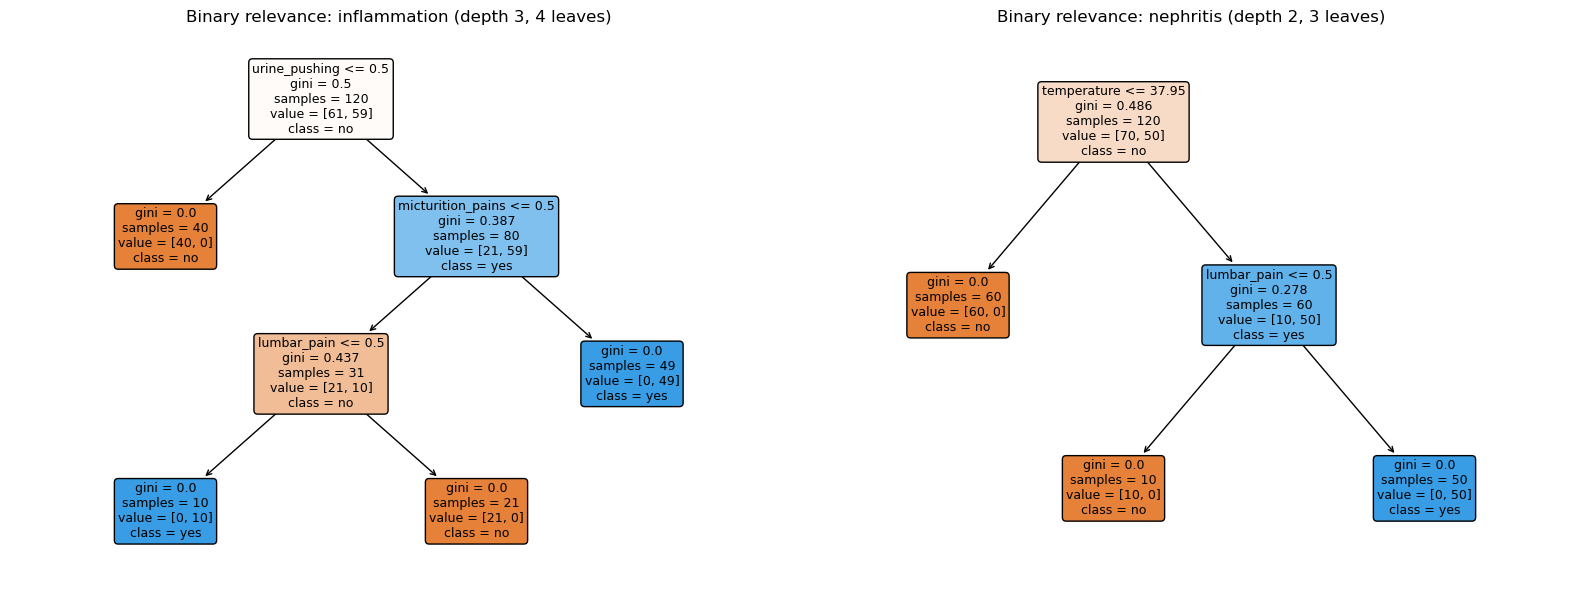

In [6]:
tree_mo = DecisionTreeClassifier(random_state=SEED).fit(X_ai, Y_ai)
print("multi-output tree: depth", tree_mo.get_depth(), "| leaves", tree_mo.get_n_leaves(),
      "| exact-match training accuracy",
      (tree_mo.predict(X_ai) == Y_ai.values).all(axis=1).mean())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, label in zip(axes, LABELS_AI):
    t = DecisionTreeClassifier(random_state=SEED).fit(X_ai, Y_ai[label])
    plot_tree(t, feature_names=FEATURES_AI, class_names=["no", "yes"], filled=True,
              rounded=True, fontsize=9, ax=ax)
    ax.set_title(f"Binary relevance: {label} (depth {t.get_depth()}, {t.get_n_leaves()} leaves)")
plt.tight_layout()
plt.show()

### (c) Converting the tree into IF-THEN rules

The function below follows the idea of the KDnuggets article in the footnote: walk the fitted tree (`tree_.children_left`, `tree_.children_right`, `tree_.feature`, `tree_.threshold`) from the root to every leaf, collect the split conditions on the path, and print one rule per leaf with the predicted class and the number of training samples that reach it. Yes/no symptoms are coded 0/1, so a split `x <= 0.5` is printed as `x = no` and `x > 0.5` as `x = yes`.

In [7]:
BINARY_FEATURES = set(FEATURES_AI[1:])


def condition(name, threshold, left):
    if name in BINARY_FEATURES:
        return f"{name} = {'no' if left else 'yes'}"
    return f"{name} {'<=' if left else '>'} {threshold:.2f}"


def tree_to_rules(model, feature_names):
    tree = model.tree_
    rules = []

    def recurse(node, conds):
        if tree.children_left[node] == tree.children_right[node]:   # leaf
            counts = tree.value[node][0]
            cls = model.classes_[np.argmax(counts)]
            n = tree.n_node_samples[node]
            rules.append((conds, cls, n))
            return
        name = feature_names[tree.feature[node]]
        thr = tree.threshold[node]
        recurse(tree.children_left[node], conds + [condition(name, thr, True)])
        recurse(tree.children_right[node], conds + [condition(name, thr, False)])

    recurse(0, [])
    return rules


def print_rules(rules):
    for i, (conds, cls, n) in enumerate(rules, 1):
        print(f"Rule {i}: IF " + " AND ".join(conds) + f"\n        THEN diagnosis = {cls}   ({n} patients)")


rules_full = tree_to_rules(tree_full, FEATURES_AI)
print_rules(rules_full)

Rule 1: IF lumbar_pain = no AND urine_pushing = no
        THEN diagnosis = none   (10 patients)
Rule 2: IF lumbar_pain = no AND urine_pushing = yes
        THEN diagnosis = inflammation only   (40 patients)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95
        THEN diagnosis = none   (20 patients)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no
        THEN diagnosis = nephritis only   (21 patients)
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no
        THEN diagnosis = nephritis only   (10 patients)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes
        THEN diagnosis = both   (19 patients)


The same tree in scikit-learn's text format, as a check of the rules above:

In [8]:
print(export_text(tree_full, feature_names=FEATURES_AI))

|--- lumbar_pain <= 0.50
|   |--- urine_pushing <= 0.50
|   |   |--- class: none
|   |--- urine_pushing >  0.50
|   |   |--- class: inflammation only
|--- lumbar_pain >  0.50
|   |--- temperature <= 37.95
|   |   |--- class: none
|   |--- temperature >  37.95
|   |   |--- micturition_pains <= 0.50
|   |   |   |--- class: nephritis only
|   |   |--- micturition_pains >  0.50
|   |   |   |--- urine_pushing <= 0.50
|   |   |   |   |--- class: nephritis only
|   |   |   |--- urine_pushing >  0.50
|   |   |   |   |--- class: both



### (d) Cost-complexity pruning

`cost_complexity_pruning_path` returns the sequence of effective alphas at which subtrees are pruned away. For every alpha, a tree is fitted and its accuracy is estimated with 5-fold stratified cross-validation (repeated over 10 shuffles to make the estimate less noisy on 120 samples). Among the alphas whose mean CV accuracy is within one standard error of the best, the **largest** alpha is chosen, which gives the smallest tree that still predicts as well as the best one (the one-standard-error rule).

In [9]:
path = tree_full.cost_complexity_pruning_path(X_ai, y_lp)
ccp_alphas = np.unique(path.ccp_alphas)
ccp_alphas = ccp_alphas[ccp_alphas < path.ccp_alphas.max()]   # drop the alpha that leaves only the root

rows = []
for a in ccp_alphas:
    scores = []
    for rep in range(10):
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=rep)
        scores.extend(cross_val_score(DecisionTreeClassifier(random_state=SEED, ccp_alpha=a),
                                      X_ai, y_lp, cv=cv))
    t = DecisionTreeClassifier(random_state=SEED, ccp_alpha=a).fit(X_ai, y_lp)
    rows.append({"ccp_alpha": a, "leaves": t.get_n_leaves(), "depth": t.get_depth(),
                 "train_acc": accuracy_score(y_lp, t.predict(X_ai)),
                 "cv_acc": np.mean(scores), "cv_se": np.std(scores, ddof=1) / np.sqrt(len(scores))})
prune_df = pd.DataFrame(rows)
prune_df

,ccp_alpha,leaves,depth,train_acc,cv_acc,cv_se
0,0.000000,6,4,1.000000,0.988333,0.003159
1,0.098167,4,2,0.841667,0.851667,0.009234
2,0.133333,3,2,0.758333,0.754167,0.008008
3,0.182000,2,1,0.591667,0.668333,0.009063


best CV accuracy 0.9883 at alpha = 0.0000
one-SE threshold 0.9852 -> chosen alpha = 0.0000


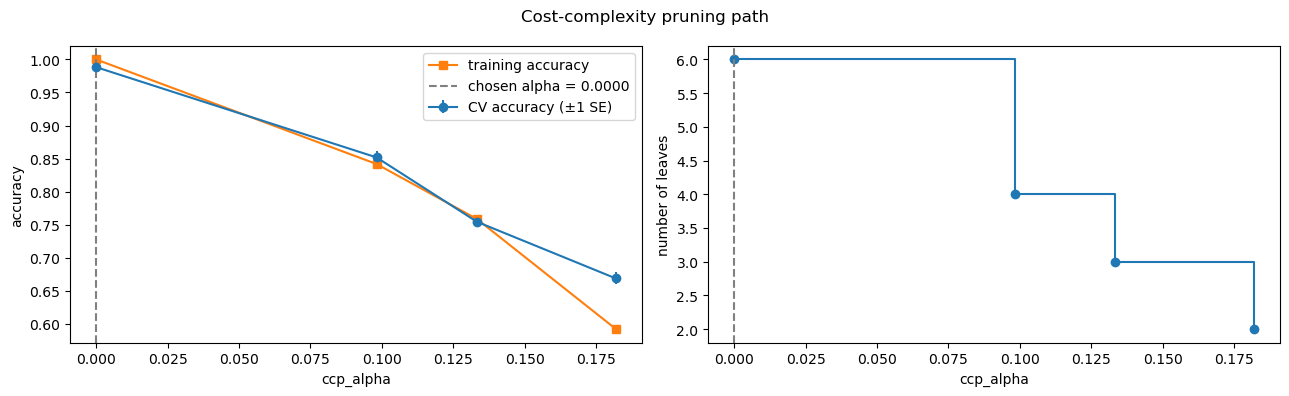

In [10]:
best = prune_df["cv_acc"].idxmax()
threshold = prune_df.loc[best, "cv_acc"] - prune_df.loc[best, "cv_se"]
chosen = prune_df[prune_df["cv_acc"] >= threshold]["ccp_alpha"].max()
print(f"best CV accuracy {prune_df.loc[best, 'cv_acc']:.4f} at alpha = {prune_df.loc[best, 'ccp_alpha']:.4f}")
print(f"one-SE threshold {threshold:.4f} -> chosen alpha = {chosen:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].errorbar(prune_df["ccp_alpha"], prune_df["cv_acc"], yerr=prune_df["cv_se"], marker="o",
                 label="CV accuracy (±1 SE)")
axes[0].plot(prune_df["ccp_alpha"], prune_df["train_acc"], marker="s", label="training accuracy")
axes[0].axvline(chosen, color="gray", ls="--", label=f"chosen alpha = {chosen:.4f}")
axes[0].set_xlabel("ccp_alpha"); axes[0].set_ylabel("accuracy"); axes[0].legend()
axes[1].step(prune_df["ccp_alpha"], prune_df["leaves"], where="post", marker="o")
axes[1].axvline(chosen, color="gray", ls="--")
axes[1].set_xlabel("ccp_alpha"); axes[1].set_ylabel("number of leaves")
fig.suptitle("Cost-complexity pruning path")
plt.tight_layout()
plt.show()

pruned tree: depth 4 | leaves 6 | training accuracy 1.0


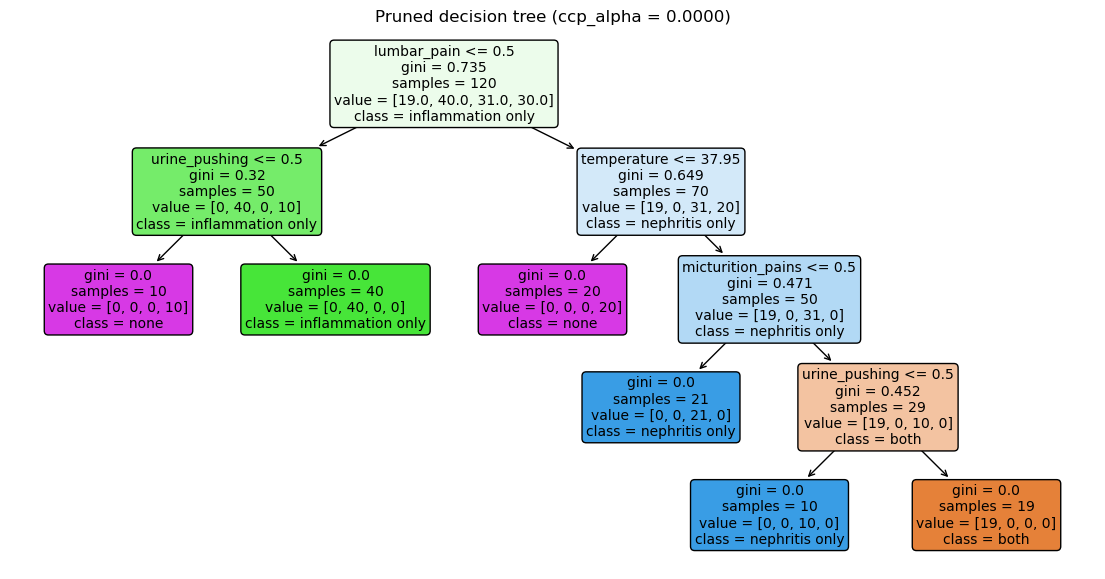

Rule 1: IF lumbar_pain = no AND urine_pushing = no
        THEN diagnosis = none   (10 patients)
Rule 2: IF lumbar_pain = no AND urine_pushing = yes
        THEN diagnosis = inflammation only   (40 patients)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95
        THEN diagnosis = none   (20 patients)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no
        THEN diagnosis = nephritis only   (21 patients)
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no
        THEN diagnosis = nephritis only   (10 patients)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes
        THEN diagnosis = both   (19 patients)


In [11]:
tree_pruned = DecisionTreeClassifier(random_state=SEED, ccp_alpha=chosen).fit(X_ai, y_lp)
print("pruned tree: depth", tree_pruned.get_depth(), "| leaves", tree_pruned.get_n_leaves(),
      "| training accuracy", accuracy_score(y_lp, tree_pruned.predict(X_ai)))

fig, ax = plt.subplots(figsize=(14, 7))
plot_tree(tree_pruned, feature_names=FEATURES_AI, class_names=list(tree_pruned.classes_),
          filled=True, rounded=True, fontsize=10, ax=ax)
ax.set_title(f"Pruned decision tree (ccp_alpha = {chosen:.4f})")
plt.show()

print_rules(tree_to_rules(tree_pruned, FEATURES_AI))

**Discussion.** The pruning path of the full tree has only four subtrees: 6 leaves (CV accuracy 98.8%), 4 leaves (85.2%), 3 leaves (75.4%) and 2 leaves (66.8%). Every pruning step costs at least 13 percentage points of accuracy, far more than one standard error, so cross-validation keeps the unpruned tree (α = 0). The 6-leaf tree is therefore already the minimal tree that diagnoses the data correctly: there are 4 diagnoses, and the "none" and "nephritis only" classes each need two leaves, because they cannot be separated from the other classes by a single split.

The 6 rules can be made shorter without changing any prediction by merging the leaves that predict the same class. This gives one rule per diagnosis:

| Rule | IF | THEN | patients |
|---|---|---|---|
| 1 | lumbar pain = no AND urine pushing = yes | inflammation of urinary bladder only | 40 |
| 2 | lumbar pain = yes AND temperature > 37.95 AND micturition pains = yes AND urine pushing = yes | both diseases | 19 |
| 3 | lumbar pain = yes AND temperature > 37.95 AND NOT (micturition pains = yes AND urine pushing = yes) | nephritis of renal pelvis origin only | 31 |
| 4 | otherwise (no lumbar pain and no urine pushing, or lumbar pain with temperature ≤ 37.95) | neither disease | 30 |

The rules agree with the medical description in `diagnosis.names`: nephritis comes with lumbar pain and a fever above 38 °C, while bladder inflammation is marked by urine pushing and micturition pains. Nausea and burning of the urethra are not needed at all.

## 2. The LASSO and Boosting for Regression

### (a) Communities and Crime data

The data was downloaded from the UCI repository and is stored in `../data/communities_and_crime/`. The column names are read from the `@attribute` lines of `communities.names`; missing values are coded as `?`. The first 1495 rows are the training set and the remaining 499 rows the test set. The response is `ViolentCrimesPerPop`.

In [12]:
CC_DIR = Path("../data/communities_and_crime")
cc_names = [line.split()[1] for line in (CC_DIR / "communities.names").read_text(encoding="latin-1").splitlines()
            if line.startswith("@attribute")]
cc = pd.read_csv(CC_DIR / "communities.data", header=None, names=cc_names, na_values="?")
TARGET = "ViolentCrimesPerPop"
print(cc.shape)
cc.iloc[:5, :12]

(1994, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,0.17,0.34
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,0.07,0.26
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,0.04,0.39
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,0.10,0.51
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,0.05,0.38


### (b) Missing values and non-predictive features

The data description lists 5 non-predictive attributes: `state`, `county`, `community`, `communityname` and `fold`. They are dropped, which leaves 122 predictive features and the goal attribute.

After dropping them, 23 features still have missing values: `OtherPerCap` has 1 missing value, and 22 police (LEMAS) features are missing for 1675 of the 1994 communities (84%). They are imputed with the **median of the training set** (the imputer is fitted on the 1495 training rows only, so no information from the test set is used). The median is robust to the skewed distributions of these features.

In [13]:
NON_PREDICTIVE = ["state", "county", "community", "communityname", "fold"]
cc = cc.drop(columns=NON_PREDICTIVE)
FEATURES_CC = [c for c in cc.columns if c != TARGET]
print("predictive features:", len(FEATURES_CC))

missing = cc[FEATURES_CC].isna().sum()
print("features with missing values:", (missing > 0).sum())
print(missing[missing > 0].sort_values(ascending=False).to_string())

predictive features: 122
features with missing values: 23
PctPolicBlack           1675
PctPolicHisp            1675
LemasGangUnitDeploy     1675
LemasPctPolicOnPatr     1675
PolicOperBudg           1675
PolicCars               1675
PolicAveOTWorked        1675
NumKindsDrugsSeiz       1675
OfficAssgnDrugUnits     1675
PctPolicMinor           1675
PctPolicAsian           1675
PolicBudgPerPop         1675
LemasSwornFT            1675
PctPolicWhite           1675
RacialMatchCommPol      1675
PolicPerPop             1675
PolicReqPerOffic        1675
LemasTotReqPerPop       1675
LemasTotalReq           1675
LemasSwFTFieldPerPop    1675
LemasSwFTFieldOps       1675
LemasSwFTPerPop         1675
OtherPerCap                1


In [14]:
N_TRAIN = 1495
train_raw, test_raw = cc.iloc[:N_TRAIN], cc.iloc[N_TRAIN:]

imputer = SimpleImputer(strategy="median").fit(train_raw[FEATURES_CC])
X_train = pd.DataFrame(imputer.transform(train_raw[FEATURES_CC]), columns=FEATURES_CC, index=train_raw.index)
X_test = pd.DataFrame(imputer.transform(test_raw[FEATURES_CC]), columns=FEATURES_CC, index=test_raw.index)
y_train, y_test = train_raw[TARGET], test_raw[TARGET]

cc_imp = pd.concat([X_train, X_test])          # the whole (imputed) data set, used in (c)-(e)
cc_imp[TARGET] = cc[TARGET]
print("train:", X_train.shape, "test:", X_test.shape, "| missing after imputation:", cc_imp.isna().sum().sum())

train: (1495, 122) test: (499, 122) | missing after imputation: 0


### (c) Correlation matrix

The correlation matrix of the 122 features (and the response, last row/column) on the whole imputed data set.

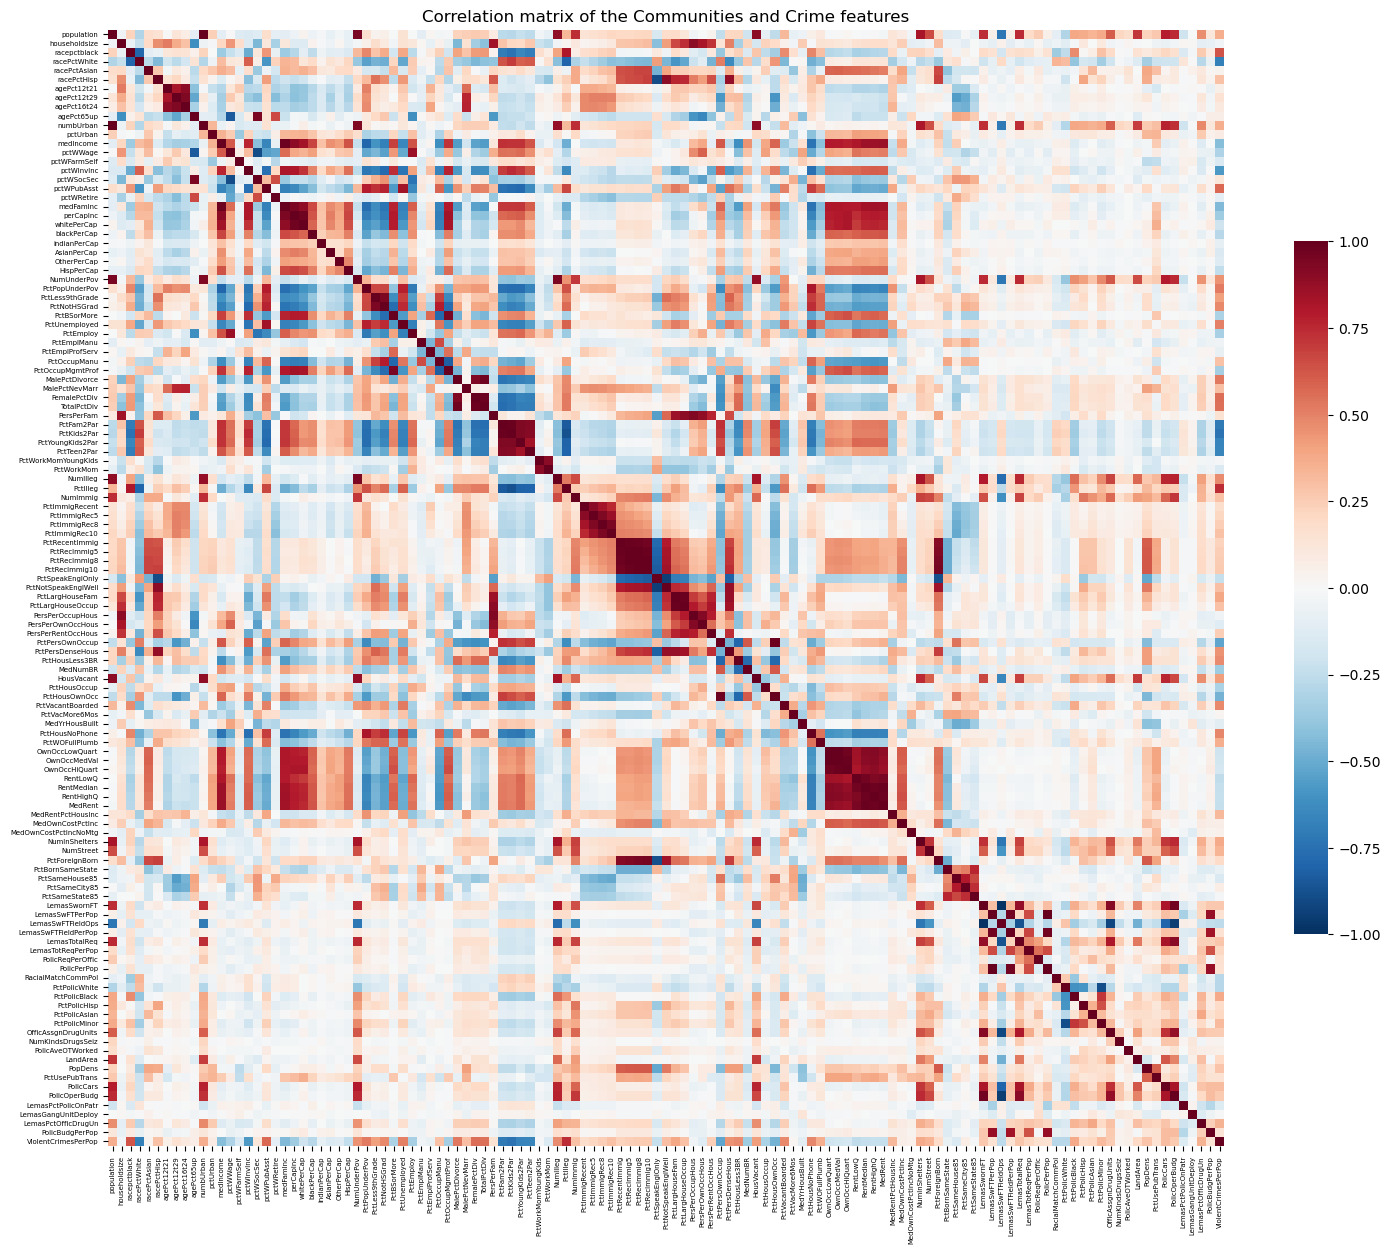

In [15]:
corr = cc_imp.corr()
fig, ax = plt.subplots(figsize=(18, 15))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, square=True, xticklabels=True, yticklabels=True,
            cbar_kws={"shrink": 0.6}, ax=ax)
ax.tick_params(labelsize=5)
ax.set_title("Correlation matrix of the Communities and Crime features")
plt.show()

In [16]:
pairs = corr.loc[FEATURES_CC, FEATURES_CC].where(np.triu(np.ones((len(FEATURES_CC),) * 2, dtype=bool), k=1)).stack()
print("feature pairs with |r| > 0.9:", (pairs.abs() > 0.9).sum(), "of", len(pairs))
print()
print("features most correlated with", TARGET)
print(corr[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False).head(10).round(3).to_string())

feature pairs with |r| > 0.9: 58 of 7381

features most correlated with ViolentCrimesPerPop
PctKids2Par        -0.738
PctIlleg            0.738
PctFam2Par         -0.707
racePctWhite       -0.685
PctYoungKids2Par   -0.666
PctTeen2Par        -0.662
racepctblack        0.631
pctWInvInc         -0.576
pctWPubAsst         0.575
FemalePctDiv        0.556


**Discussion.** The matrix has clear blocks of strongly correlated features: the income measures (`medIncome`, `medFamInc`, `perCapInc`, …), the family-structure measures (`PctFam2Par`, `PctKids2Par`, `PctYoungKids2Par`, …), the immigration measures (`PctRecImmig5/8/10`, `PctForeignBorn`, …), the count variables that grow with city size (`population`, `numbUrban`, `NumUnderPov`, `NumIlleg`, …) and the police (LEMAS) variables. 58 feature pairs have |r| > 0.9. This multicollinearity makes plain least squares unstable and is the motivation for the shrinkage and dimension-reduction methods in (g)–(j). The response is most strongly related to family structure (`PctKids2Par`, r = −0.74; `PctIlleg`, r = +0.74) and to race and income variables.

### (d) Coefficient of variation

$CV = s / m$ with $s$ the sample standard deviation and $m$ the sample mean of each feature (whole imputed data set).

In [17]:
cv_table = pd.DataFrame({"mean": cc_imp[FEATURES_CC].mean(), "std": cc_imp[FEATURES_CC].std(ddof=1)})
cv_table["CV"] = cv_table["std"] / cv_table["mean"]
cv_table = cv_table.sort_values("CV", ascending=False)
print(cv_table.round(4).to_string())

                         mean     std      CV
PctPolicAsian          0.0184  0.1001  5.4478
NumStreet              0.0228  0.1004  4.4077
NumInShelters          0.0294  0.1026  3.4855
NumIlleg               0.0363  0.1087  2.9942
NumImmig               0.0301  0.0872  2.9005
LemasPctOfficDrugUn    0.0941  0.2403  2.5553
NumUnderPov            0.0555  0.1279  2.3050
population             0.0576  0.1269  2.2035
LemasSwornFT           0.0279  0.0581  2.0807
numbUrban              0.0641  0.1283  2.0017
HousVacant             0.0768  0.1505  1.9588
LandArea               0.0652  0.1095  1.6780
racePctHisp            0.1440  0.2325  1.6143
PolicOperBudg          0.0375  0.0586  1.5629
PctNotSpeakEnglWell    0.1506  0.2197  1.4591
PctUsePubTrans         0.1617  0.2291  1.4167
racepctblack           0.1796  0.2534  1.4109
LemasTotalReq          0.0493  0.0681  1.3817
racePctAsian           0.1537  0.2089  1.3592
PctPolicHisp           0.0636  0.0843  1.3263
PctRecentImmig         0.1814  0.2

### (e) The ⌊√128⌋ = 11 features with the highest CV

In [18]:
k = int(np.floor(np.sqrt(128)))
top_cv = cv_table.index[:k].tolist()
print(k, "features:", top_cv)

11 features: ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'LemasSwornFT', 'numbUrban', 'HousVacant']


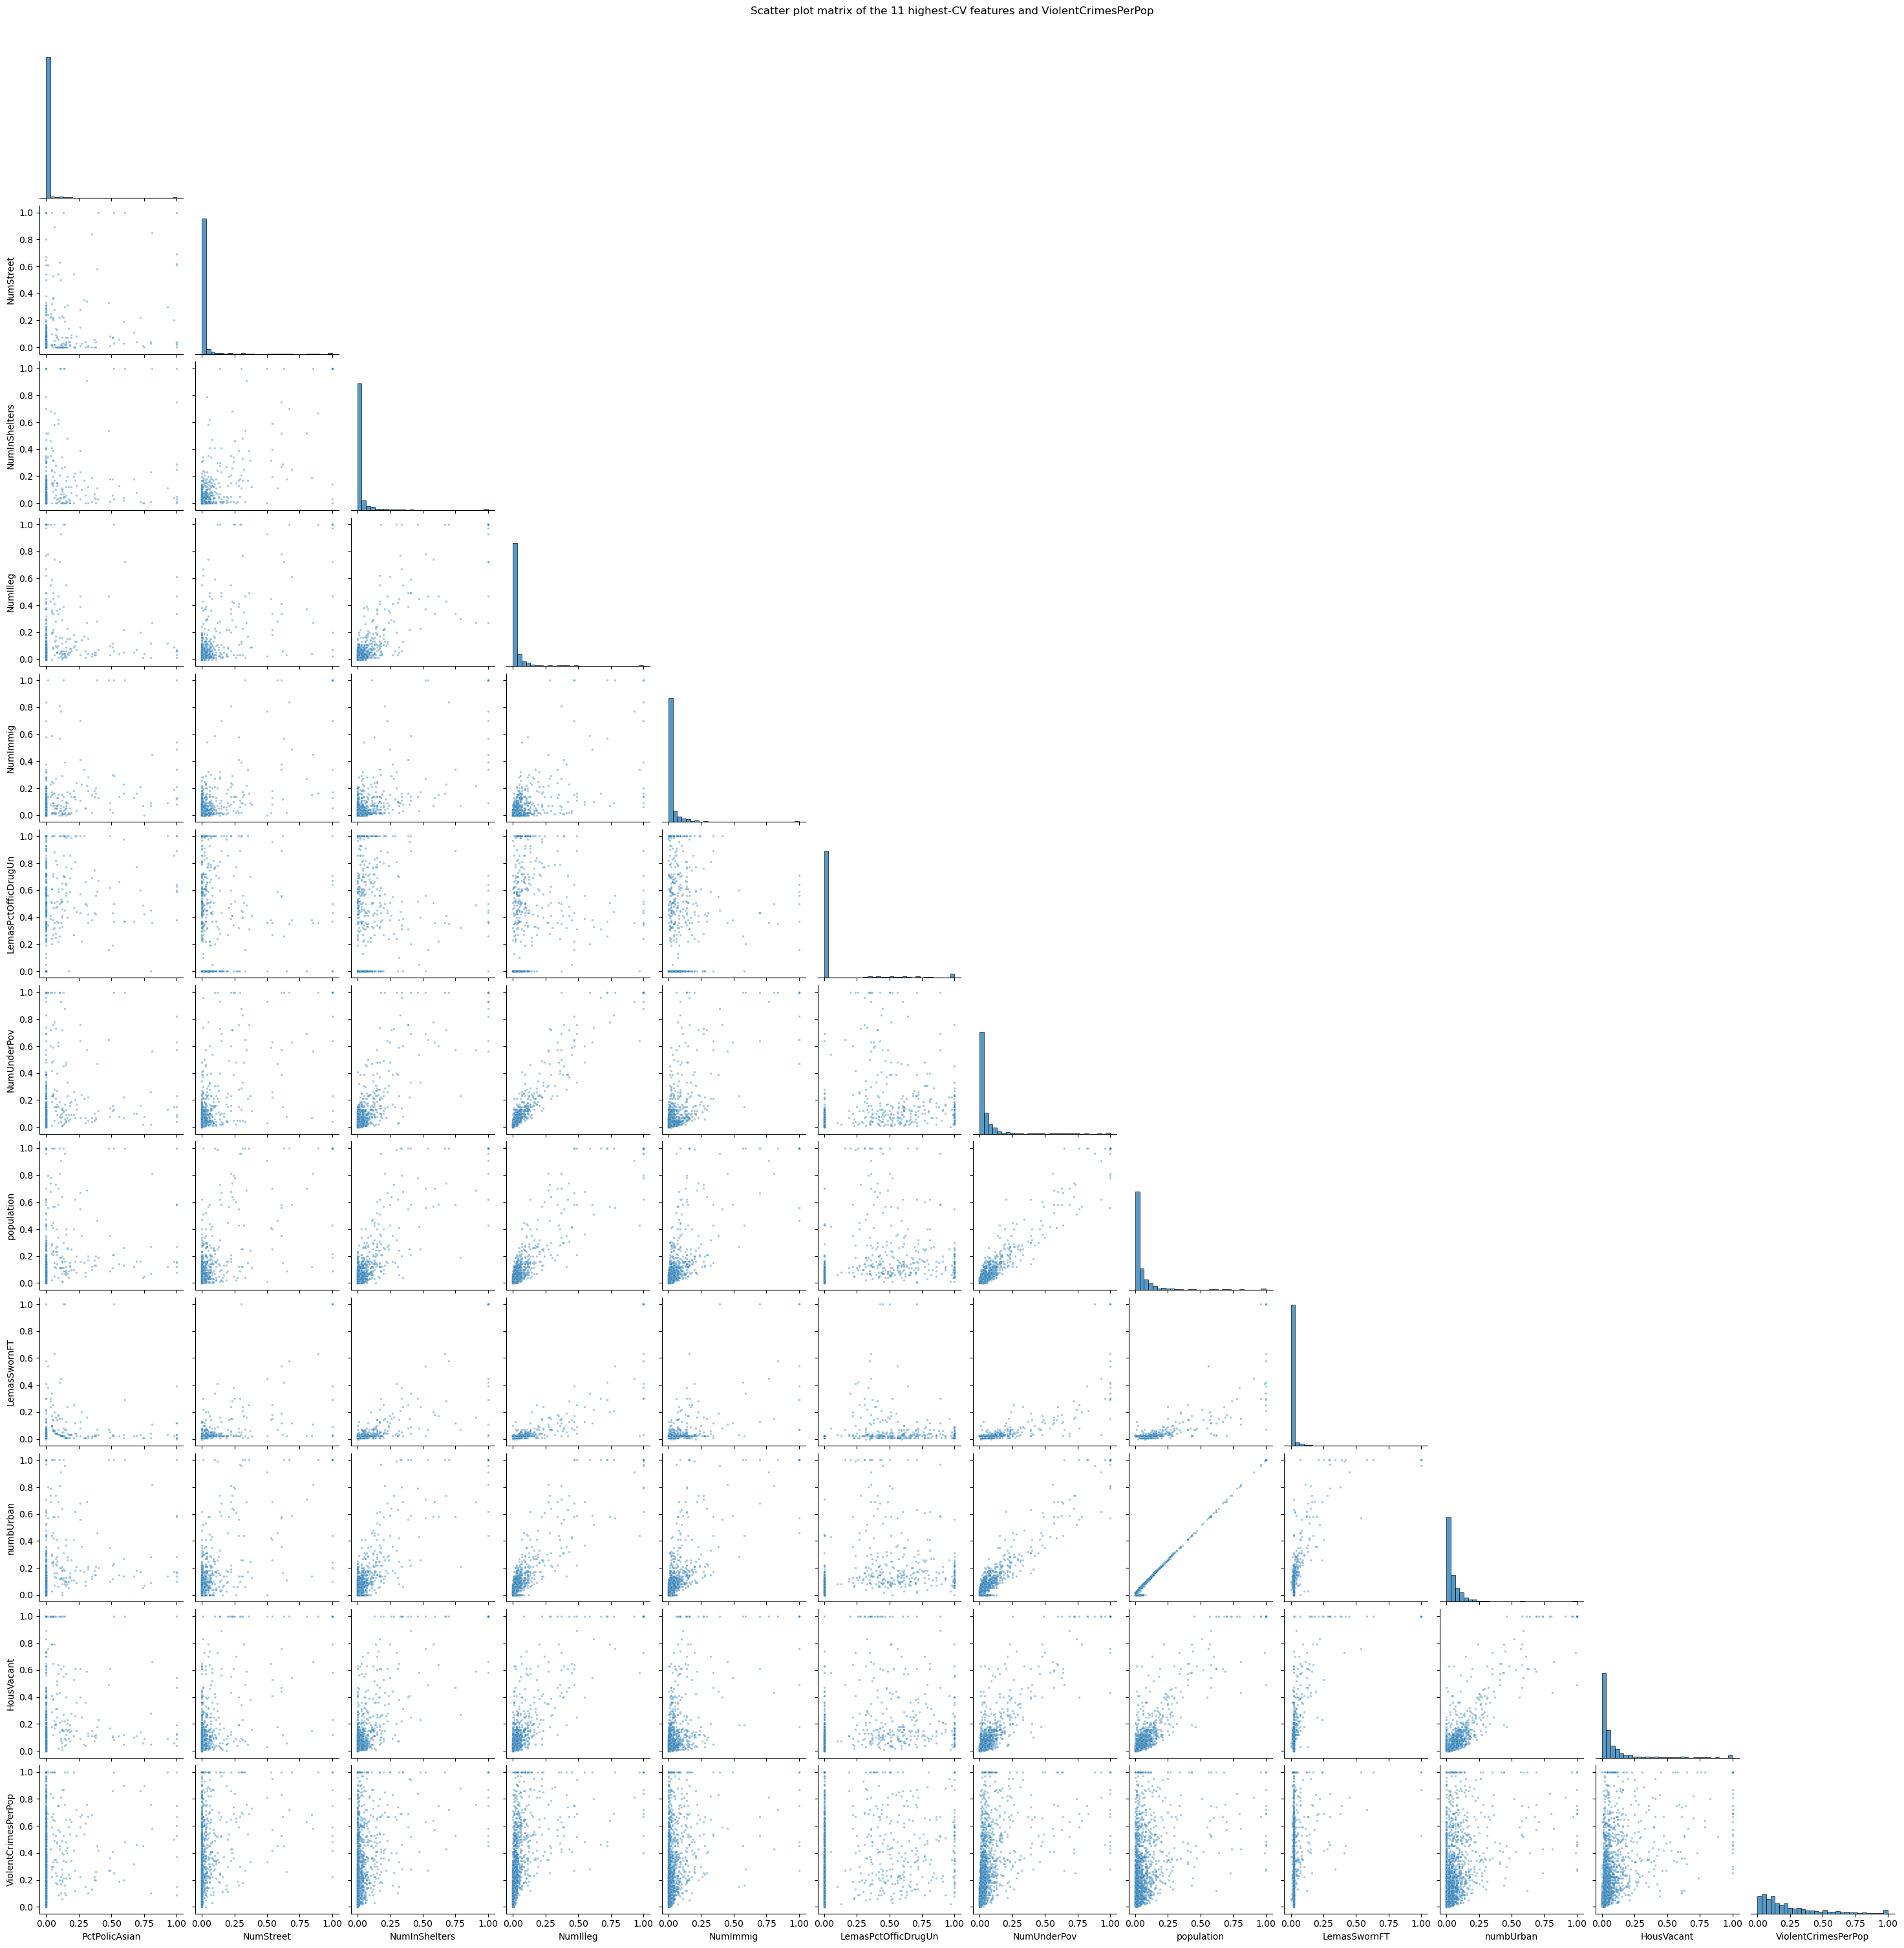

In [19]:
g = sns.pairplot(cc_imp[top_cv + [TARGET]], corner=True, plot_kws={"s": 6, "alpha": 0.4},
                 diag_kws={"bins": 30})
g.figure.suptitle(f"Scatter plot matrix of the {k} highest-CV features and {TARGET}", y=1.01)
plt.show()

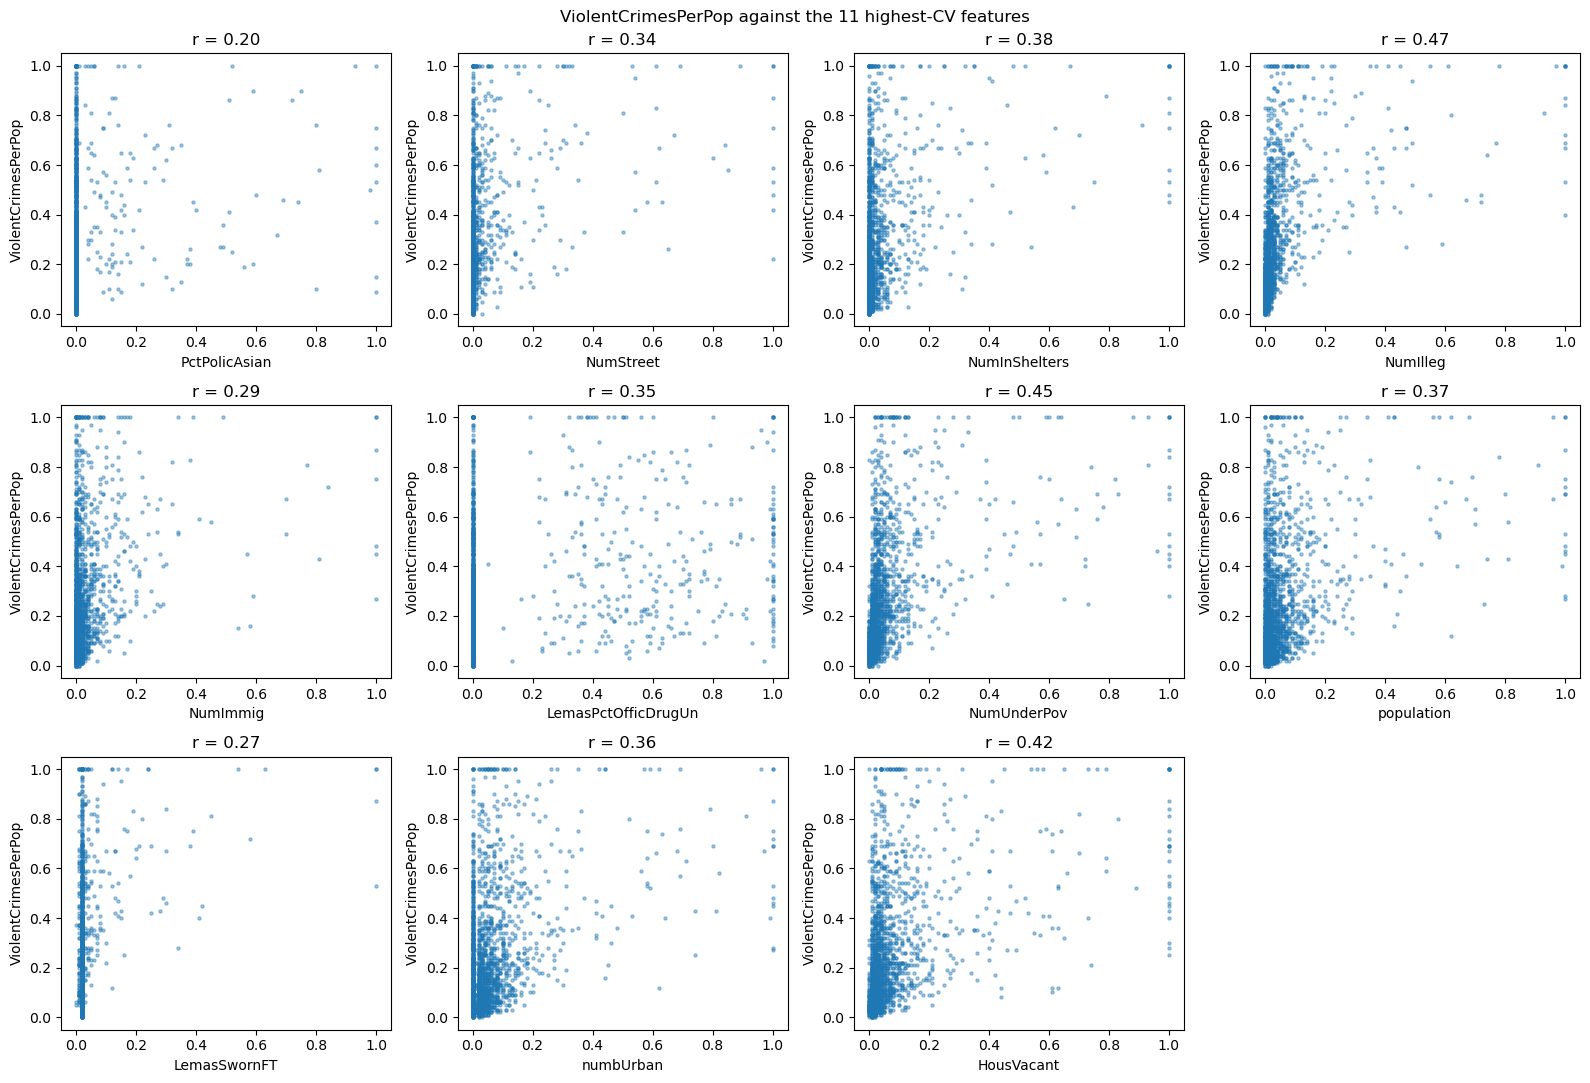

In [20]:
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, f in zip(axes.flat, top_cv):
    ax.scatter(cc_imp[f], cc_imp[TARGET], s=5, alpha=0.4)
    ax.set_xlabel(f); ax.set_ylabel(TARGET)
    ax.set_title(f"r = {cc_imp[f].corr(cc_imp[TARGET]):.2f}")
axes.flat[-1].axis("off")
fig.suptitle(f"{TARGET} against the {k} highest-CV features")
plt.tight_layout()
plt.show()

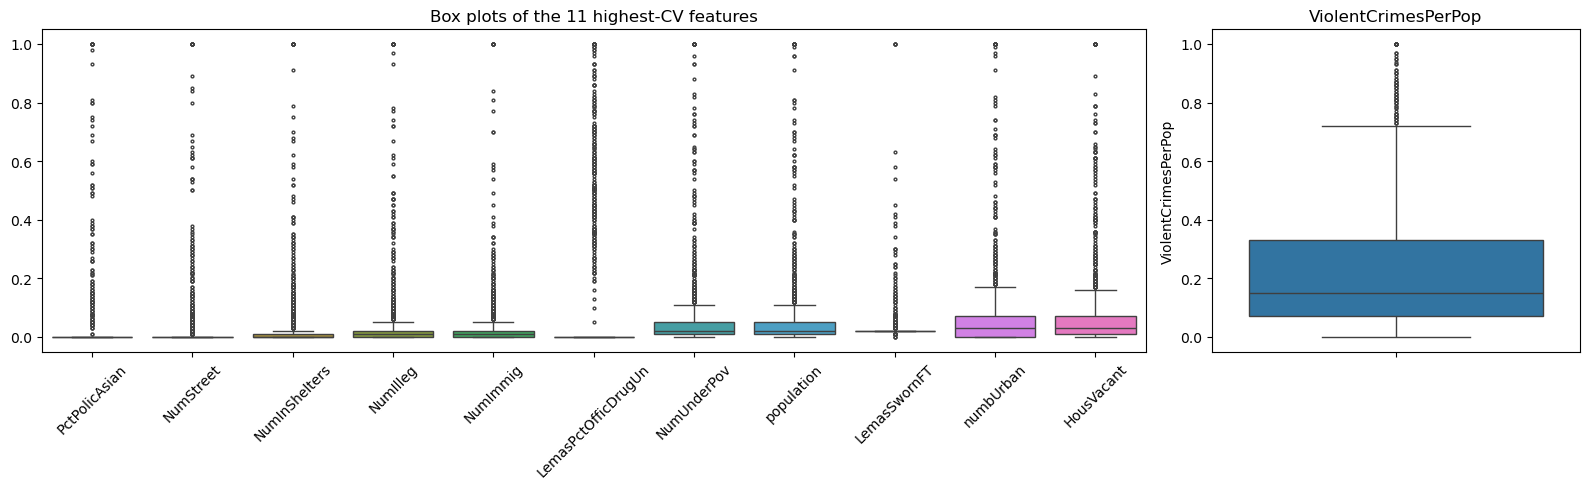

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [3, 1]})
sns.boxplot(data=cc_imp[top_cv], ax=axes[0], fliersize=2)
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_title(f"Box plots of the {k} highest-CV features")
sns.boxplot(y=cc_imp[TARGET], ax=axes[1], fliersize=2)
axes[1].set_title(TARGET)
plt.tight_layout()
plt.show()

**Discussion.** The features with the highest CV are those whose mean is close to zero with a long right tail. Eight of them are counts that grow with community size (`NumStreet`, `NumInShelters`, `NumIlleg`, `NumImmig`, `NumUnderPov`, `population`, `numbUrban`, `HousVacant`): after the donors' min-max normalization, 70–92% of the communities have a value ≤ 0.05 and a few large cities are spread out up to 1. `PctPolicAsian` and `LemasSwornFT` are police features that were missing for 84% of the communities, so median imputation puts about 90% of their values at one point; the high CV partly comes from the imputation. `LemasPctOfficDrugUn` is 0 for 85% of the communities.

**Can we conclude anything about significance from the scatter plots? Not really.** The scatter plots show that `ViolentCrimesPerPop` tends to be higher in the few communities with large values of these features (correlations 0.20–0.47), but most points are piled up near 0, where the response covers its whole range. A scatter plot only shows the marginal relation of one feature with the response. It ignores the other 121 features, many of which are strongly correlated with these ones (the count variables are all proxies for city size), and it gives no measure of uncertainty. Whether a feature is significant must be judged in a model with the other features, e.g. with a t-test of its coefficient, or by whether the LASSO keeps it. A high CV also says nothing about predictive power: it only measures spread relative to the mean.

### (f) Linear model fitted by least squares

The test error is reported as the test mean squared error (MSE) throughout Problem 2.

In [22]:
results = {}

ols = LinearRegression().fit(X_train, y_train)
results["Least squares"] = mean_squared_error(y_test, ols.predict(X_test))
print(f"least squares: train MSE = {mean_squared_error(y_train, ols.predict(X_train)):.5f}, "
      f"test MSE = {results['Least squares']:.5f}")

least squares: train MSE = 0.01629, test MSE = 147604790152182848.00000


The least-squares test error is enormous although the training error is small. The cell below shows why: the training design matrix is rank deficient, because two features are identical on all 1495 training rows.

In [23]:
print("rank of the training design matrix:", np.linalg.matrix_rank(X_train.values), "of", X_train.shape[1], "columns")
dup = [(a, b) for i, a in enumerate(FEATURES_CC) for b in FEATURES_CC[i + 1:] if X_train[a].equals(X_train[b])]
print("identical columns in the training set:", dup)
a, b = dup[0]
print(f"coefficients: {a} = {ols.coef_[FEATURES_CC.index(a)]:.4g}, {b} = {ols.coef_[FEATURES_CC.index(b)]:.4g}")
diff = X_test[a] - X_test[b]
print(f"test rows where {a} != {b}:", (diff != 0).sum())
print(X_test.loc[diff != 0, [a, b]].assign(**{TARGET: y_test[diff != 0]}))

sq_err = (y_test - ols.predict(X_test)) ** 2
print()
print(f"largest squared test error: {sq_err.max():.4g} (row {sq_err.idxmax()}); "
      f"test MSE without that row: {sq_err.drop(sq_err.idxmax()).mean():.5f}")

rank of the training design matrix: 121 of 122 columns
identical columns in the training set: [('LemasSwFTPerPop', 'PolicPerPop')]
coefficients: LemasSwFTPerPop = -8.582e+11, PolicPerPop = 8.582e+11
test rows where LemasSwFTPerPop != PolicPerPop: 1
      LemasSwFTPerPop  PolicPerPop  ViolentCrimesPerPop
1640             0.28         0.29                 0.79

largest squared test error: 7.365e+19 (row 1640); test MSE without that row: 0.01788


In [24]:
FEATURES_OLS = [f for f in FEATURES_CC if f != b]
ols2 = LinearRegression().fit(X_train[FEATURES_OLS], y_train)
results["Least squares (duplicate dropped)"] = mean_squared_error(y_test, ols2.predict(X_test[FEATURES_OLS]))
print(f"least squares without {b}: train MSE = {mean_squared_error(y_train, ols2.predict(X_train[FEATURES_OLS])):.5f}, "
      f"test MSE = {results['Least squares (duplicate dropped)']:.5f}")

least squares without PolicPerPop: train MSE = 0.01629, test MSE = 0.01797


**Discussion.** `LemasSwFTPerPop` (sworn full-time police officers per 100K population) and `PolicPerPop` (police officers per 100K population) have exactly the same values on all 1495 training rows (including the imputed ones), so the least-squares problem has no unique solution. The minimum-norm solution returned by `LinearRegression` puts huge coefficients of opposite sign (±8.6 × 10¹¹) on the two copies; they cancel in the training set, so the training MSE is a normal 0.01629. In the test set the two features differ in a single community (row 1640: 0.28 vs 0.29), and that difference of 0.01 is multiplied by 8.6 × 10¹¹, which gives a squared error of 7 × 10¹⁹ and a test MSE of 1.5 × 10¹⁷. Without that one row the test MSE is 0.01788. Dropping one of the two duplicate columns makes the problem full rank, and the least-squares model then has **test MSE = 0.01797**. This is the value used to compare least squares with the other models below. It is a concrete example of how unstable unpenalized least squares becomes with collinear features.

### (g) Ridge regression, λ chosen by cross-validation

λ (`alpha` in scikit-learn) is searched over a log grid from 1e-3 to 1e4 with 10-fold cross-validation on the training set.

In [25]:
kf = KFold(n_splits=10, shuffle=True, random_state=SEED)
ridge_alphas = np.logspace(-3, 4, 100)
ridge = RidgeCV(alphas=ridge_alphas, cv=kf, scoring="neg_mean_squared_error").fit(X_train, y_train)
results["Ridge"] = mean_squared_error(y_test, ridge.predict(X_test))
print(f"ridge: lambda = {ridge.alpha_:.4f}, test MSE = {results['Ridge']:.5f}")

ridge: lambda = 2.1049, test MSE = 0.01753


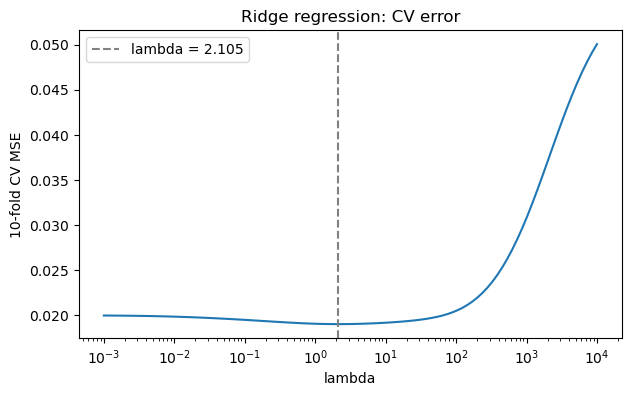

In [26]:
ridge_cv = [-cross_val_score(RidgeCV(alphas=[a]), X_train, y_train, cv=kf,
                             scoring="neg_mean_squared_error").mean() for a in ridge_alphas]
plt.figure(figsize=(7, 4))
plt.semilogx(ridge_alphas, ridge_cv)
plt.axvline(ridge.alpha_, color="gray", ls="--", label=f"lambda = {ridge.alpha_:.3f}")
plt.xlabel("lambda"); plt.ylabel("10-fold CV MSE"); plt.title("Ridge regression: CV error")
plt.legend(); plt.show()

### (h) LASSO, λ chosen by cross-validation

`LassoCV` computes the regularization path over 100 values of λ and picks the one with the smallest 10-fold CV error. The model is fitted twice: on the features as given (they are already normalized to [0, 1] by the data donors) and on standardized features (zero mean, unit variance, scaler fitted on the training set inside a pipeline).

In [27]:
lasso = LassoCV(cv=kf, n_alphas=100, max_iter=100000, random_state=SEED).fit(X_train, y_train)
results["LASSO"] = mean_squared_error(y_test, lasso.predict(X_test))
sel = pd.Series(lasso.coef_, index=FEATURES_CC)
sel = sel[sel != 0].sort_values(key=np.abs, ascending=False)
print(f"LASSO (features as given): lambda = {lasso.alpha_:.6f}, test MSE = {results['LASSO']:.5f}")
print(f"{len(sel)} of {len(FEATURES_CC)} variables selected:")
print(sel.round(4).to_string())

LASSO (features as given): lambda = 0.000082, test MSE = 0.01769
79 of 122 variables selected:
agePct12t29             -0.3203
racepctblack             0.2698
PctPersDenseHous         0.2382
PctKids2Par             -0.2014
MedRent                  0.1830
PctEmploy                0.1755
MalePctNevMarr           0.1723
RentLowQ                -0.1714
NumStreet                0.1638
PctPopUnderPov          -0.1601
MalePctDivorce           0.1467
PctWorkMom              -0.1416
HousVacant               0.1311
pctWInvInc              -0.1271
FemalePctDiv            -0.1195
PersPerOccupHous         0.1176
NumImmig                -0.1175
pctWRetire              -0.1114
PctLargHouseOccup       -0.1111
NumIlleg                -0.1090
PolicReqPerOffic         0.1044
pctWWage                -0.1007
PctNotSpeakEnglWell     -0.0955
PctIlleg                 0.0932
MedRentPctHousInc        0.0913
agePct12t21              0.0837
whitePerCap             -0.0825
LemasSwFTFieldPerPop     0.0815
MedOwnCos

In [28]:
lasso_std = Pipeline([("scale", StandardScaler()),
                      ("lasso", LassoCV(cv=kf, n_alphas=100, max_iter=100000, random_state=SEED))])
lasso_std.fit(X_train, y_train)
results["LASSO (standardized)"] = mean_squared_error(y_test, lasso_std.predict(X_test))
m = lasso_std.named_steps["lasso"]
sel_std = pd.Series(m.coef_, index=FEATURES_CC)
sel_std = sel_std[sel_std != 0].sort_values(key=np.abs, ascending=False)
print(f"LASSO (standardized): lambda = {m.alpha_:.6f}, test MSE = {results['LASSO (standardized)']:.5f}")
print(f"{len(sel_std)} of {len(FEATURES_CC)} variables selected:")
print(sel_std.round(4).to_string())

LASSO (standardized): lambda = 0.000619, test MSE = 0.01773
76 of 122 variables selected:
racepctblack             0.0681
agePct12t29             -0.0438
PctPersDenseHous         0.0437
PctKids2Par             -0.0406
RentLowQ                -0.0311
MedRent                  0.0309
PctPopUnderPov          -0.0297
PctEmploy                0.0255
MalePctNevMarr           0.0251
PctIlleg                 0.0238
PctWorkMom              -0.0225
pctWInvInc              -0.0223
MalePctDivorce           0.0216
pctWRetire              -0.0179
HousVacant               0.0176
NumStreet                0.0175
pctUrban                 0.0172
MedRentPctHousInc        0.0153
PctVacantBoarded         0.0151
FemalePctDiv            -0.0151
MedOwnCostPctIncNoMtg   -0.0147
pctWWage                -0.0145
PctNotSpeakEnglWell     -0.0135
agePct12t21              0.0127
PctLargHouseOccup       -0.0126
PctHousOccup            -0.0119
PctPersOwnOccup         -0.0117
PctHousLess3BR           0.0115
NumImmig      

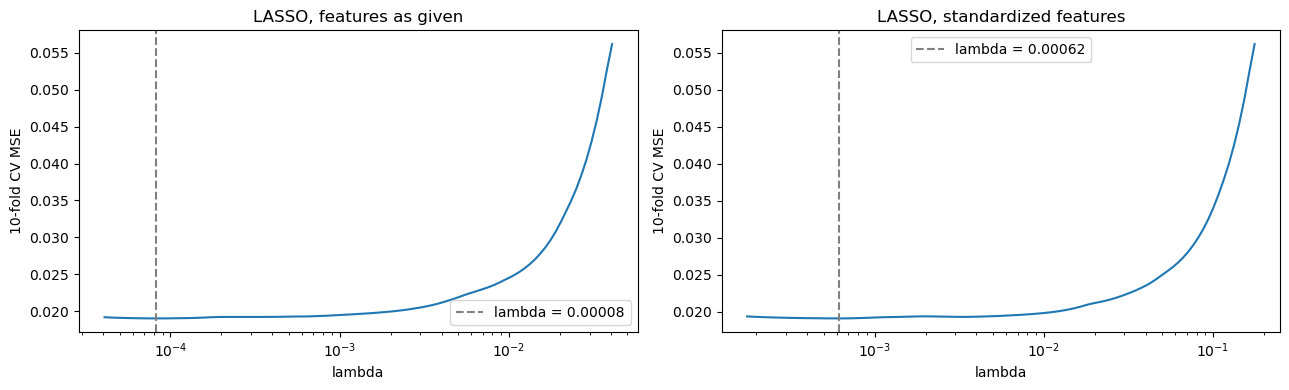

selected in both: 75 | only unstandardized: 4 | only standardized: 1


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, model, title in [(axes[0], lasso, "features as given"),
                         (axes[1], lasso_std.named_steps["lasso"], "standardized features")]:
    mse = model.mse_path_.mean(axis=1)
    ax.semilogx(model.alphas_, mse)
    ax.axvline(model.alpha_, color="gray", ls="--", label=f"lambda = {model.alpha_:.5f}")
    ax.set_xlabel("lambda"); ax.set_ylabel("10-fold CV MSE"); ax.set_title(f"LASSO, {title}")
    ax.legend()
plt.tight_layout()
plt.show()

common = sorted(set(sel.index) & set(sel_std.index))
print(f"selected in both: {len(common)} | only unstandardized: {len(set(sel.index) - set(sel_std.index))} "
      f"| only standardized: {len(set(sel_std.index) - set(sel.index))}")

**Discussion.** With the features as given, LASSO keeps 79 of the 122 variables and has test MSE 0.01769; with standardized features it keeps 76 variables and has test MSE 0.01773. The two fits are almost the same: 75 variables are selected in both, and the test errors differ in the fourth decimal. This is expected, because the features are already min-max normalized to [0, 1] by the data donors, so their scales are similar (standard deviations 0.05–0.45) and standardizing changes the relative penalty on each coefficient only a little. The variables with the largest standardized coefficients are `racepctblack`, `agePct12t29`, `PctPersDenseHous`, `PctKids2Par`, `RentLowQ`, `MedRent` and `PctPopUnderPov`. Both LASSO fits are close to ridge regression in test error.

### (i) Principal components regression, M chosen by cross-validation

The features are standardized, projected on the first M principal components (fitted on the training folds only, inside the pipeline) and a least-squares model is fitted on the components. M = 1, …, 122 is chosen by 10-fold cross-validation.

PCR: M = 97, CV MSE = 0.01948, test MSE = 0.01837


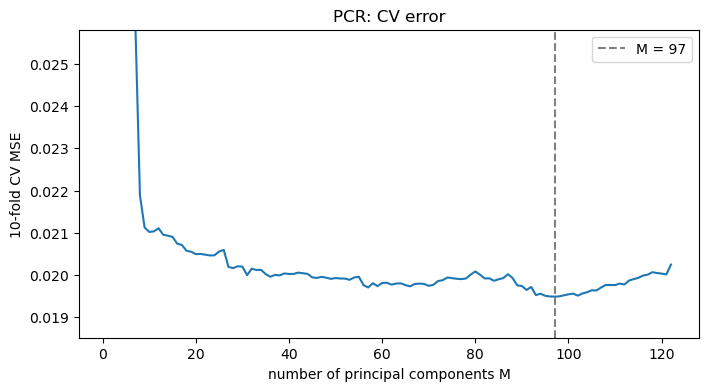

In [30]:
pcr = Pipeline([("scale", StandardScaler()), ("pca", PCA()), ("ols", LinearRegression())])
pcr_search = GridSearchCV(pcr, {"pca__n_components": range(1, len(FEATURES_CC) + 1)}, cv=kf,
                          scoring="neg_mean_squared_error").fit(X_train, y_train)
best_m = pcr_search.best_params_["pca__n_components"]
results["PCR"] = mean_squared_error(y_test, pcr_search.predict(X_test))
print(f"PCR: M = {best_m}, CV MSE = {-pcr_search.best_score_:.5f}, test MSE = {results['PCR']:.5f}")

pcr_cv = -pcr_search.cv_results_["mean_test_score"]
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(FEATURES_CC) + 1), pcr_cv)
plt.axvline(best_m, color="gray", ls="--", label=f"M = {best_m}")
plt.xlabel("number of principal components M"); plt.ylabel("10-fold CV MSE")
plt.title("PCR: CV error"); plt.ylim(pcr_cv.min() * 0.95, np.percentile(pcr_cv, 95)); plt.legend()
plt.show()

**Discussion.** The CV error falls sharply over the first ~10 components, stays nearly flat around 0.020 between M ≈ 30 and M ≈ 95, reaches its minimum 0.01948 at M = 97 and rises again when the last components are added. The minimum is shallow, so PCR is not much simpler than least squares here. Its test MSE (0.01837) is a little worse than ridge and LASSO: the principal components are chosen without looking at the response, and some of the low-variance directions that PCR drops still carry information about crime.

### (j) L1-penalized gradient boosting tree (XGBoost)

`XGBRegressor` fits a gradient-boosted regression tree ensemble; its `reg_alpha` parameter adds an L1 penalty α·Σ|w| on the leaf weights of every tree, which shrinks the leaf values and sets small ones to zero. α is chosen by 10-fold cross-validation over a log grid; the other settings are held fixed at moderate values for a small data set (300 trees, learning rate 0.05, depth 3, 80% row and column subsampling).

XGBoost: alpha = 2.154, CV MSE = 0.01913, test MSE = 0.01593


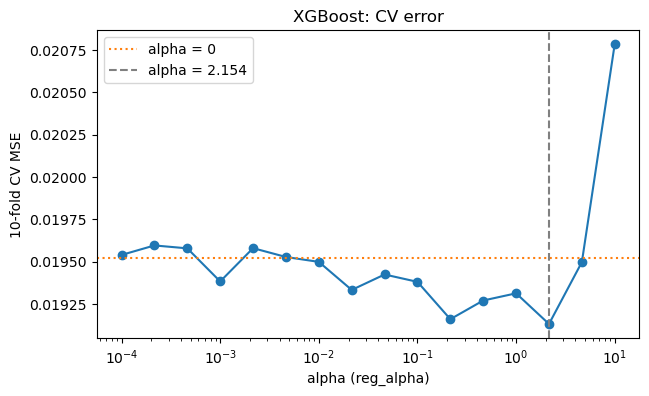

In [31]:
xgb = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8,
                   colsample_bytree=0.8, objective="reg:squarederror", random_state=SEED, n_jobs=-1)
xgb_alphas = np.concatenate([[0], np.logspace(-4, 1, 16)])
xgb_search = GridSearchCV(xgb, {"reg_alpha": xgb_alphas}, cv=kf,
                          scoring="neg_mean_squared_error").fit(X_train, y_train)
best_alpha = xgb_search.best_params_["reg_alpha"]
results["XGBoost (L1)"] = mean_squared_error(y_test, xgb_search.predict(X_test))
print(f"XGBoost: alpha = {best_alpha:.4g}, CV MSE = {-xgb_search.best_score_:.5f}, "
      f"test MSE = {results['XGBoost (L1)']:.5f}")

xgb_cv = -xgb_search.cv_results_["mean_test_score"]
plt.figure(figsize=(7, 4))
plt.semilogx(xgb_alphas[1:], xgb_cv[1:], marker="o")
plt.axhline(xgb_cv[0], color="tab:orange", ls=":", label="alpha = 0")
if best_alpha > 0:
    plt.axvline(best_alpha, color="gray", ls="--", label=f"alpha = {best_alpha:.4g}")
plt.xlabel("alpha (reg_alpha)"); plt.ylabel("10-fold CV MSE"); plt.title("XGBoost: CV error")
plt.legend(); plt.show()

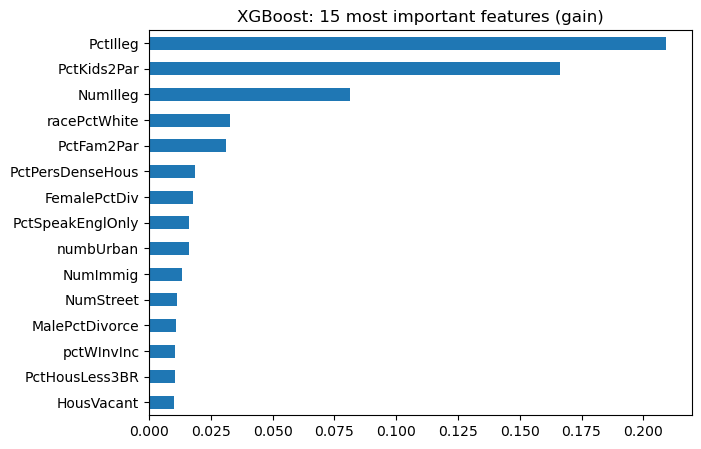

In [32]:
imp = pd.Series(xgb_search.best_estimator_.feature_importances_, index=FEATURES_CC)
imp.sort_values().tail(15).plot.barh(figsize=(7, 5), title="XGBoost: 15 most important features (gain)")
plt.show()

### Summary of test errors

In [33]:
summary = pd.DataFrame({"test MSE": results})
summary["test RMSE"] = np.sqrt(summary["test MSE"])
summary.round(5)

,test MSE,test RMSE
Least squares,1.476048e+17,3.841937e+08
Least squares (duplicate dropped),1.797000e-02,1.340400e-01
Ridge,1.753000e-02,1.323900e-01
LASSO,1.769000e-02,1.329900e-01
LASSO (standardized),1.773000e-02,1.331400e-01
PCR,1.837000e-02,1.355300e-01
XGBoost (L1),1.593000e-02,1.262200e-01


**Discussion.** For XGBoost, the CV error is fairly flat (0.0192–0.0196) for α ≤ 2 and rises sharply for α = 10, where the L1 penalty shrinks the leaf weights too much. Cross-validation chooses α ≈ 2.15. The CV curve is noisy for small α, so any α between about 0.01 and 2 would give a similar model.

The linear models are close to each other: least squares (after removing the duplicate column) 0.01797, LASSO 0.01769 / 0.01773, ridge 0.01753 and PCR 0.01837. Shrinkage helps a little over least squares because the 122 features are strongly correlated. The L1-penalized boosting tree has the lowest test error (MSE 0.01593, RMSE 0.126), about 9% lower than ridge. Trees can capture non-linear effects and interactions that the linear models miss, such as the threshold-like relations seen in the scatter plots. Its most important features (`PctIlleg`, `PctKids2Par`, `racePctWhite`, …) are the same family-structure and race variables that have the largest correlations with the response and the largest LASSO coefficients.